# 04 — From score to probability: the softmax and the *forward pass*

**Chapter 1** · suggested time: 20 min · CPU only · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/chapter_1/04_softmax_forward_pass.ipynb)

![Chapter roadmap](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_1/figures/00_roadmap.png)

**Where are we?**
- **Notebook 02:** a **loss** scores a model from the probability it gives to the correct answer: $-\log(p)$.
- **Notebook 03:** `one_hot(x) @ W` gives **27 scores** for each current character.
- **What is missing:** these scores are not probabilities, so we cannot apply the loss to them.

We need a transformation that guarantees two properties: every value **between 0 and 1**, and the 27 values of a row **summing to 1**.

**Why not store probabilities directly in `W`?** Because by freely changing a weight during training, we could create a negative number or break the sum to 1. So we let `W` hold **unconstrained scores**, called **logits**, and transform them afterwards. Training can then change `W` however it likes.

In [1]:
# On Google Colab: fetch the course repository (corpus + shared modules such as bigram.py).
# Locally, this cell does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("bigram.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/chapter_1

In [2]:
# Setup: imports and the chapter's small shared module
import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

import bigram  # the file bigram.py, next to this notebook
from bigram import SEED, plot_char_matrix

words = bigram.load_names()
chars, stoi, itos = bigram.build_vocabulary(words)
print(f"{len(words):,} names · vocabulary of {len(stoi)} symbols · PyTorch {torch.__version__}")

N = bigram.count_bigrams(words, stoi)
P = N.float() / N.sum(dim=1, keepdim=True)

32,033 names · vocabulary of 27 symbols · PyTorch 2.15.0+cu132


## 1. First problem: negative scores

Three made-up characters `a`, `b`, `c`, with these logits:

| next character | `a` | `b` | `c` |
|---|---:|---:|---:|
| logit | −1 | 0 | 1 |

The score 1 expresses a stronger **preference** for `c`. But 1 is not "100%", and −1 cannot be a probability.

We need a function that:
- makes **any real number strictly positive**;
- **preserves the order**: a higher score keeps a larger weight;
- is **differentiable**, so we can train `W` with gradients.

The **exponential** ticks all three boxes: $e^{-1}\approx 0.368$, $e^0=1$, $e^1\approx 2.718$.

> In code, these values are often called `counts`, by analogy with counts. They **are not** the counts of `N`. Section 4 shows why the analogy is nonetheless very apt.

a: logit = -1.0  →  exp(logit) = 0.368
b: logit = +0.0  →  exp(logit) = 1.000
c: logit = +1.0  →  exp(logit) = 2.718
Sum of the weights: 4.086 → not 1 yet


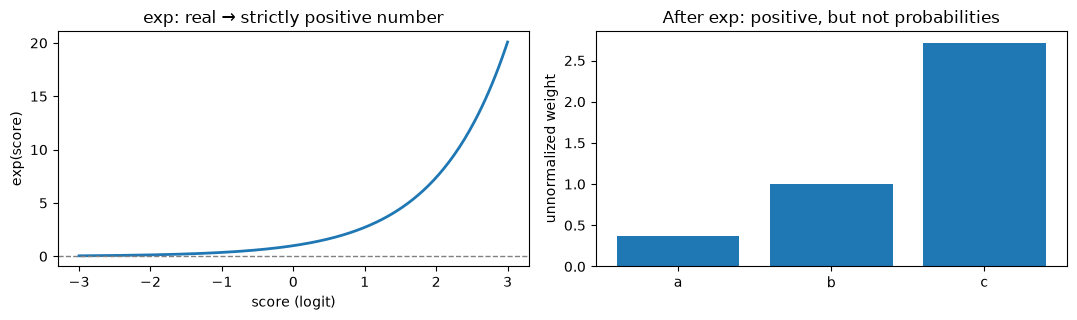

In [3]:
toy_logits = torch.tensor([-1.0, 0.0, 1.0])
toy_weights = toy_logits.exp()

for c, s, w in zip("abc", toy_logits, toy_weights):
    print(f"{c}: logit = {s.item():+.1f}  →  exp(logit) = {w.item():.3f}")
print("Sum of the weights:", round(toy_weights.sum().item(), 3), "→ not 1 yet")

z = torch.linspace(-3, 3, 250)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].plot(z.numpy(), z.exp().numpy(), linewidth=2)
axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[0].set(title="exp: real → strictly positive number", xlabel="score (logit)", ylabel="exp(score)")
axes[1].bar(list("abc"), toy_weights.numpy())
axes[1].set(title="After exp: positive, but not probabilities", ylabel="unnormalized weight")
plt.tight_layout(); plt.show()

## 2. Second problem: the sum is not 1

The weights are about $[0.368;\ 1;\ 2.718]$, summing to $\approx 4.086$. As in notebook 01, to turn positive weights into proportions, **we divide each one by the sum**:

$$
p_j = \frac{e^{s_j}}{\sum_k e^{s_k}}.
$$

Here we get $[0.090;\ 0.245;\ 0.665]$. Each value is between 0 and 1 and they sum to 1.

The combination **exponential, then division by the sum** is called the **softmax**. The name comes from the fact that it behaves like a "softened" `max`: the largest score gets the largest share, without the others dropping to zero.

> **Do not confuse:** the softmax computes a **distribution**. It does not pick a character. It is `torch.multinomial` (notebook 01) that draws a character from this distribution.

a: logit = -1.0 | exp = 0.368 | p = 0.090
b: logit = +0.0 | exp = 1.000 | p = 0.245
c: logit = +1.0 | exp = 2.718 | p = 0.665
Same as torch.softmax: yes


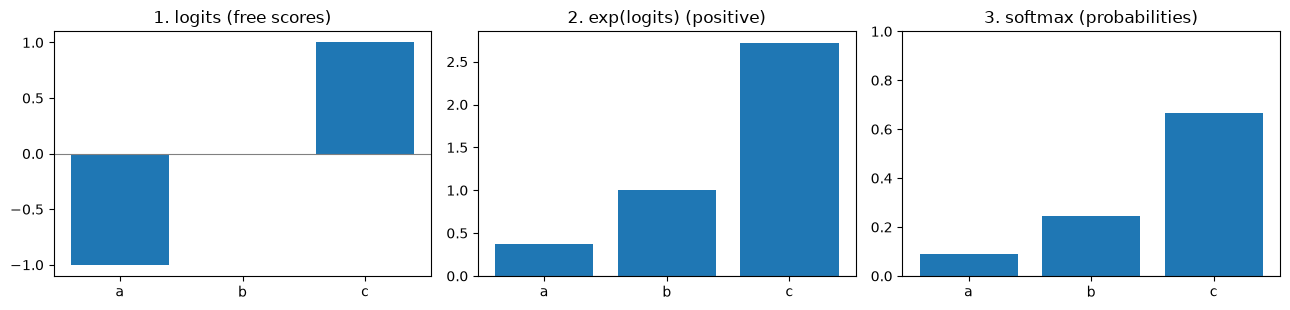

In [4]:
toy_probs = toy_weights / toy_weights.sum()
for c, s, w, p in zip("abc", toy_logits, toy_weights, toy_probs):
    print(f"{c}: logit = {s.item():+.1f} | exp = {w.item():.3f} | p = {p.item():.3f}")
assert torch.allclose(toy_probs, torch.softmax(toy_logits, dim=0))
print("Same as torch.softmax: yes")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, val, title in zip(axes, [toy_logits, toy_weights, toy_probs],
                          ["1. logits (free scores)", "2. exp(logits) (positive)", "3. softmax (probabilities)"]):
    ax.bar(list("abc"), val.numpy()); ax.set_title(title); ax.axhline(0, color="gray", linewidth=0.8)
axes[2].set_ylim(0, 1)
plt.tight_layout(); plt.show()

## 3. Three softmax properties to know

1. **Adding the same constant to every logit changes nothing.** $e^{s_j + c} / \sum_k e^{s_k + c}$: the factor $e^c$ cancels out. Only the **differences** between scores matter.
2. **Multiplying the logits by a number** makes the distribution sharper (factor > 1) or flatter (factor < 1). This is the idea behind **temperature**, used in chapter 2 for generation.
3. **Very large logits make `exp` overflow** (`exp(1000) = inf`). `torch.softmax` uses property 1: it subtracts the maximum before applying `exp`, and the result stays exact.

In [5]:
s = torch.tensor([-1.0, 0.0, 1.0])
print("softmax(s)       :", torch.softmax(s, 0).round(decimals=3).tolist())
print("softmax(s + 100) :", torch.softmax(s + 100, 0).round(decimals=3).tolist(), " ← identical")
print("softmax(3 * s)   :", torch.softmax(3 * s, 0).round(decimals=3).tolist(), " ← sharper")
print("softmax(s / 3)   :", torch.softmax(s / 3, 0).round(decimals=3).tolist(), " ← flatter")

large = torch.tensor([1000.0, 1001.0, 1002.0])
naive = large.exp() / large.exp().sum()
print("\nNaive version on [1000, 1001, 1002]:", naive.tolist())
print("torch.softmax                      :", torch.softmax(large, 0).round(decimals=3).tolist())

softmax(s)       : [0.09000000357627869, 0.24500000476837158, 0.6650000214576721]
softmax(s + 100) : [0.09000000357627869, 0.24500000476837158, 0.6650000214576721]  ← identical
softmax(3 * s)   : [0.0020000000949949026, 0.04699999839067459, 0.949999988079071]  ← sharper
softmax(s / 3)   : [0.23000000417232513, 0.32100000977516174, 0.4480000138282776]  ← flatter

Naive version on [1000, 1001, 1002]: [nan, nan, nan]
torch.softmax                      : [0.09000000357627869, 0.24500000476837158, 0.6650000214576721]


## 4. The remark that ties everything together: logits are "log-counts"

Why call the values `exp(logits)` `counts`? Suppose we choose $W_{ij} = \log N_{ij}$. Then

$$
\mathrm{softmax}(W_i)_j = \frac{e^{\log N_{ij}}}{\sum_k e^{\log N_{ik}}} = \frac{N_{ij}}{\sum_k N_{ik}} = P_{ij}.
$$

The softmax of this matrix gives back **exactly the counts table**. In other words, the right answer **exists** among all possible values of `W`. Training will have to find it on its own, without ever seeing `N`. Zero counts are a problem (`log 0 = −∞`), so we use the smoothed version `N + 1` from notebook 02.

In [6]:
W_log = (N + 1).float().log()              # logits = log of the (smoothed) counts
P_smooth = (N + 1).float() / (N + 1).sum(dim=1, keepdim=True)
print("softmax(log(N+1)) == smoothed P?", torch.allclose(torch.softmax(W_log, dim=1), P_smooth, atol=1e-6))

softmax(log(N+1)) == smoothed P? True


## 5. The full *forward pass* on `emma`

![Forward pass](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_1/figures/04_forward_pass.png)

We now apply the recipe with **27 characters** and the **5 transitions of `emma`**. `W` is drawn at random (`torch.randn`), without using `N` or `P`: its predictions are therefore **untrained**.

1. `xenc = F.one_hot(xs_small)`: 5 inputs of 27 slots → `(5, 27)`;
2. `logits = xenc @ W`: the 5 rows of scores selected from `W` → `(5, 27)`;
3. `counts = logits.exp()`: strictly positive weights → `(5, 27)`;
4. `probs = counts / counts.sum(dim=1, keepdim=True)`: **each row** divided by **its own** sum → `(5, 27)`.

`dim=1` corresponds to the 27 output characters: we normalize **each example separately**, without mixing the 5 examples. `keepdim=True` gives sums of shape `(5, 1)`, as in notebook 01.

In [7]:
sequence = ["."] + list("emma") + ["."]
transitions = list(zip(sequence, sequence[1:]))
xs_small = torch.tensor([stoi[a] for a, b in transitions])
ys_small = torch.tensor([stoi[b] for a, b in transitions])

g = torch.Generator().manual_seed(SEED)
W = torch.randn((27, 27), generator=g)

# THE FOUR LINES TO REMEMBER: the forward pass of the neural bigram
xenc = F.one_hot(xs_small, num_classes=27).float()             # (5, 27) inputs
logits = xenc @ W                                              # (5, 27) free scores
counts = logits.exp()                                          # (5, 27) positive (this is NOT N)
probs = counts / counts.sum(dim=1, keepdim=True)               # (5, 27) probabilities

print("Row sums before division:", counts.sum(dim=1).round(decimals=2).tolist())
print("Row sums after division :", probs.sum(dim=1).round(decimals=4).tolist())
print("Same as F.softmax(logits, dim=1)?", torch.allclose(probs, F.softmax(logits, dim=1)))

Row sums before division: [79.01000213623047, 55.33000183105469, 38.90999984741211, 38.90999984741211, 34.15999984741211]
Row sums after division : [1.0, 1.0, 1.0, 1.0, 1.0]


Same as F.softmax(logits, dim=1)? True


## 6. Reading a probability *produced by the network*

We now have two answers to the same question: "after `m`, what is the probability of `a`?"
- **Table `P` (notebook 01):** `P[stoi['m'], stoi['a']]`, an **observed frequency**;
- **Untrained network:** `probs[3, stoi['a']]`, the softmax of row `W['m']`. Example no. 4 of `emma` happens to be `m → a` (index 3 in Python).

These two numbers have **no reason to be close** for now: `W` is random.

m → a according to counts P: 0.3899
m → a according to random W: 0.0737


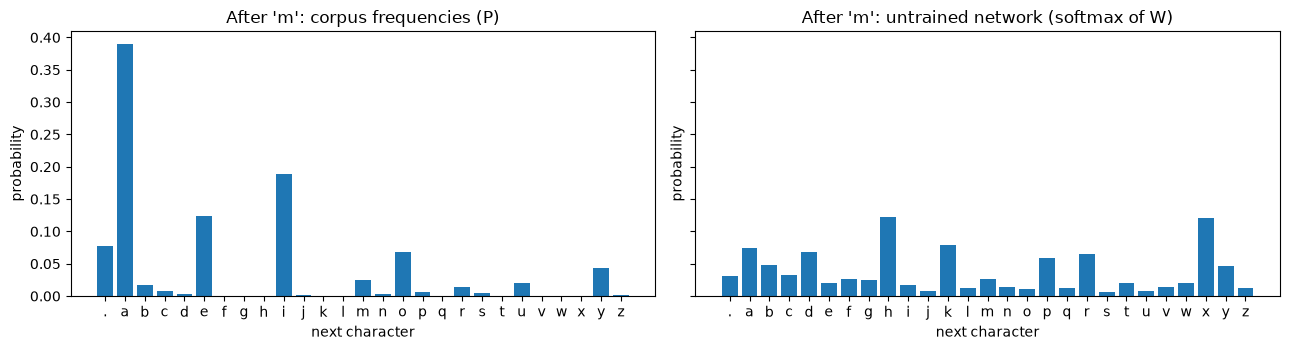

In [8]:
i_m, i_a = stoi["m"], stoi["a"]
print(f"m → a according to counts P: {P[i_m, i_a].item():.4f}")
print(f"m → a according to random W: {probs[3, i_a].item():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, dist, title in zip(axes, [P[i_m], probs[3]],
                           ["After 'm': corpus frequencies (P)", "After 'm': untrained network (softmax of W)"]):
    ax.bar(range(27), dist.numpy())
    ax.set_xticks(range(27), [itos[i] for i in range(27)])
    ax.set(title=title, xlabel="next character", ylabel="probability")
plt.tight_layout(); plt.show()

## 7. The loss becomes computable

The loop started in notebook 02 closes:
- the **correct answers** `ys_small` are known;
- `probs` holds 5 rows of **predicted probabilities**;
- in each row, we read **the probability of the correct answer** and compute the **same mean NLL** as before.

For example $t$, the relevant probability is `probs[t, ys_small[t]]`, and its penalty is $-\log$ of that probability.

In [9]:
p_true = probs[torch.arange(5), ys_small]      # one probability per example (explained in notebook 05)
costs = -p_true.log()
for (a, b), p, c in zip(transitions, p_true, costs):
    print(f"  {a} → {b}: p = {p.item():.4f}   −log p = {c.item():.3f}")
print(f"Mean NLL of the random network on emma: {costs.mean().item():.3f}")

P_smooth = (N + 1).float() / (N + 1).sum(dim=1, keepdim=True)
print(f"NLL of table P on emma                : {-P_smooth[xs_small, ys_small].log().mean().item():.3f}")

  . → e: p = 0.0123   −log p = 4.399
  e → m: p = 0.0181   −log p = 4.015
  m → m: p = 0.0267   −log p = 3.623
  m → a: p = 0.0737   −log p = 2.608
  a → .: p = 0.0150   −log p = 4.201
Mean NLL of the random network on emma: 3.769
NLL of table P on emma                : 2.514


The random network does **much worse** than counting, and even worse than uniform (3.30). That is expected: it has learned nothing.

**Careful:** computing the loss **does not change `W`**. To improve the predictions, we need to know **which way to move each weight** to lower the loss. That is the job of the **gradients**, in notebook 05.

## Summary

$$
\boxed{\text{indices}\xrightarrow{\text{one-hot}}(n,27)\xrightarrow{@W}\text{logits}\xrightarrow{\exp}\text{counts}\xrightarrow{/\text{sum}}\text{probs}\xrightarrow{[\,\cdot\,,\,y]}p_\text{true}\xrightarrow{-\log,\ \text{mean}}\text{loss}}
$$

- **logits** = free scores, any real number;
- **softmax** = `exp` then normalization, which gives a distribution;
- `softmax(log N) = P`: counting is **one particular value** of `W`.

The *forward pass* is done; learning can begin.

## References
- J. S. Bridle, *Probabilistic Interpretation of Feedforward Classification Network Outputs, with Relationships to Statistical Pattern Recognition*, 1990: the paper that popularized the name "softmax".
- I. Goodfellow, Y. Bengio and A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), 2016, section 6.2.2.3 "Softmax Units" and section 4.1 (numerical overflow and stable softmax).
- Andrej Karpathy, [*The spelled-out intro to language modeling: building makemore*](https://www.youtube.com/watch?v=PaCmpygFfXo) (2022) and the [makemore](https://github.com/karpathy/makemore) repository, where `names.txt` and the spirit of this chapter come from.